# Inside a Decoder Transformer, Step by Step

**What you'll learn**
- How text becomes tokens, and tokens become vectors
- Attention by hand: scores, scaling, softmax, the causal mask
- Multi-head attention and what real heads look at
- Logits, context, and generation as a loop
- How a decoder is trained

## Setup
- Qwen2.5-0.5B-Instruct: a small decoder that fits any GPU
- No training in this notebook, so gradients are switched off
- Library warnings are switched off to keep the outputs readable

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM, logging

torch.set_grad_enabled(False)
logging.set_verbosity_error()

In [2]:
MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, device_map="cuda")
model

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

## Tokenization: How Text Becomes Tokens
- `Ġ` marks a leading space

In [3]:
ids = tok("It's time for tea.")["input_ids"]
ids

[2132, 594, 882, 369, 15243, 13]

In [4]:
tok.convert_ids_to_tokens(ids)

['It', "'s", 'Ġtime', 'Ġfor', 'Ġtea', '.']

In [5]:
ids = tok("unbelievably ")["input_ids"]
tok.convert_ids_to_tokens(ids)

['un', 'belie', 'vably', 'Ġ']

In [6]:
len(tok)

151665

## From Token IDs to Vectors
- One row per token id

In [7]:
E = model.model.embed_tokens.weight.float()
E.shape

torch.Size([151936, 896])

In [8]:
tea_id = tok.encode(" tea")[0]
tea = E[tea_id]  # the vector for " tea"
tea.shape

torch.Size([896])

In [9]:
# how close every token's vector is to it
similarity = torch.cosine_similarity(E, tea[None], dim=-1)
similarity.shape

torch.Size([151936])

In [10]:
top = similarity.topk(10)

for i in top.indices:
    print(tok.decode(i))

 tea
 Tea
茶
tea
 teas
茶叶
 coffee
coffee
喝茶
红茶


- Tea in other languages sits close to ` tea` too

## Self-Attention Step by Step: Scores, Scaling, Softmax
- Four tokens, 8 numbers each, a head of size 4

In [11]:
torch.manual_seed(0)
X = torch.randn(4, 8)
Wq = torch.randn(8, 4) / math.sqrt(8)
Wk = torch.randn(8, 4) / math.sqrt(8)
Wv = torch.randn(8, 4) / math.sqrt(8)
X

tensor([[-1.1258, -1.1524, -0.2506, -0.4339,  0.8487,  0.6920, -0.3160, -2.1152],
        [ 0.3223, -1.2633,  0.3500,  0.3081,  0.1198,  1.2377,  1.1168, -0.2473],
        [-1.3527, -1.6959,  0.5667,  0.7935,  0.5988, -1.5551, -0.3414,  1.8530],
        [ 0.7502, -0.5855, -0.1734,  0.1835,  1.3894,  1.5863,  0.9463, -0.8437]])

In [12]:
Q = X @ Wq
K = X @ Wk
V = X @ Wv
Q.shape

torch.Size([4, 4])

In [13]:
scores = (Q @ K.T) / math.sqrt(4)
scores

tensor([[ 0.7635,  0.2847, -0.4822,  0.6666],
        [-1.2153, -0.1276, -0.8091,  0.2573],
        [-0.1877, -0.3487,  0.1254, -0.4579],
        [-1.4361, -0.1442, -1.3603,  0.4546]])

In [14]:
weights = torch.softmax(scores, dim=-1)
weights

tensor([[0.3552, 0.2201, 0.1022, 0.3224],
        [0.1017, 0.3019, 0.1527, 0.4436],
        [0.2511, 0.2138, 0.3434, 0.1917],
        [0.0810, 0.2949, 0.0874, 0.5367]])

In [15]:
weights.sum(dim=-1)

tensor([1., 1., 1., 1.])

In [16]:
out = weights @ V
out

tensor([[ 0.9502, -0.3241, -0.2500, -0.6852],
        [ 1.1327, -0.3864,  0.1902, -0.4594],
        [ 0.8674,  0.2653,  0.1599, -0.3794],
        [ 1.1864, -0.6340,  0.1394, -0.5130]])

### Causal Mask
- A token may only look at itself and the tokens before it

In [17]:
mask = torch.tril(torch.ones(4, 4)).bool()
mask

tensor([[ True, False, False, False],
        [ True,  True, False, False],
        [ True,  True,  True, False],
        [ True,  True,  True,  True]])

In [18]:
# -inf wherever a token would look ahead
masked = scores.masked_fill(~mask, float("-inf"))
masked

tensor([[ 0.7635,    -inf,    -inf,    -inf],
        [-1.2153, -0.1276,    -inf,    -inf],
        [-0.1877, -0.3487,  0.1254,    -inf],
        [-1.4361, -0.1442, -1.3603,  0.4546]])

In [19]:
causal_weights = torch.softmax(masked, dim=-1)
causal_weights

tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.2520, 0.7480, 0.0000, 0.0000],
        [0.3107, 0.2645, 0.4249, 0.0000],
        [0.0810, 0.2949, 0.0874, 0.5367]])

- Above the diagonal is 0: no token looks ahead
- PyTorch has the same thing built in

In [20]:
torch.nn.functional.scaled_dot_product_attention(Q, K, V, is_causal=True)

tensor([[ 0.4644, -0.1060, -1.3465, -1.2355],
        [ 1.3065,  0.1847,  0.0644, -0.6232],
        [ 0.7935,  0.7012,  0.2017, -0.3259],
        [ 1.1864, -0.6340,  0.1394, -0.5130]])

In [21]:
causal_weights @ V

tensor([[ 0.4644, -0.1060, -1.3465, -1.2355],
        [ 1.3065,  0.1847,  0.0644, -0.6232],
        [ 0.7935,  0.7012,  0.2017, -0.3259],
        [ 1.1864, -0.6340,  0.1394, -0.5130]])

## Multi-Head Attention: Several Heads in Parallel
- Qwen splits 896 numbers into 14 heads of 64

In [22]:
x = torch.randn(5, 896)
heads = x.view(5, 14, 64)
heads.shape

torch.Size([5, 14, 64])

## What Real Heads Look At
- The default attention is fast but cannot hand back its weights, so switch to `eager`

In [23]:
model.set_attn_implementation("eager")

x = tok("The cat sat on the mat because it was tired.", return_tensors="pt").to("cuda")
response = model(**x, output_attentions=True)
len(response.attentions), response.attentions[0].shape

(24, torch.Size([1, 14, 11, 11]))

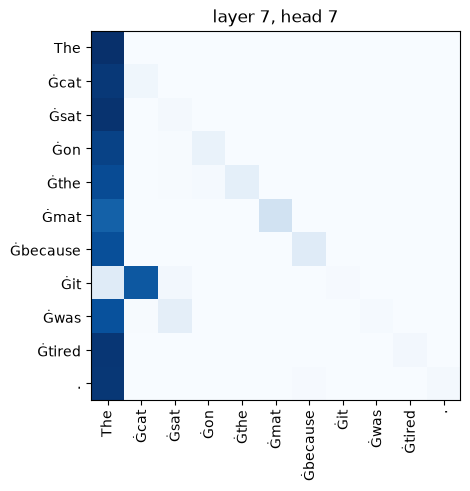

In [24]:
tokens = tok.convert_ids_to_tokens(x["input_ids"][0])
A = response.attentions[7][0, 7].float().cpu()  # layer 7, first text, head 7

plt.imshow(A, cmap="Blues")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.title("layer 7, head 7")
plt.show()

- Find the row for `Ġit`: which word does it look at?

## Inside One Transformer Block: Attention Plus MLP
- Attention mixes the tokens, the MLP works on each token

In [25]:
layer = model.model.layers[0]
layer

Qwen2DecoderLayer(
  (self_attn): Qwen2Attention(
    (q_proj): Linear(in_features=896, out_features=896, bias=True)
    (k_proj): Linear(in_features=896, out_features=128, bias=True)
    (v_proj): Linear(in_features=896, out_features=128, bias=True)
    (o_proj): Linear(in_features=896, out_features=896, bias=False)
  )
  (mlp): Qwen2MLP(
    (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
    (up_proj): Linear(in_features=896, out_features=4864, bias=False)
    (down_proj): Linear(in_features=4864, out_features=896, bias=False)
    (act_fn): SiLUActivation()
  )
  (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
  (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
)

In [26]:
mlp = 0
for p in layer.mlp.parameters():
    mlp += p.numel()  # every weight in the MLP

attention = 0
for p in layer.self_attn.parameters():
    attention += p.numel()  # every weight in attention

mlp, attention

(13074432, 1836160)

- The MLP holds about 7 times the weights of attention

## Logits: The Model Scores Every Possible Next Token

In [27]:
x = tok("It's time for", return_tensors="pt").to("cuda")
logits = model(**x).logits
logits.shape

torch.Size([1, 4, 151936])

In [28]:
last = logits[0, -1].float()  # the scores for the token after "for"
last.shape

torch.Size([151936])

In [29]:
probs = last.softmax(dim=-1)
top = probs.topk(5)
tok.convert_ids_to_tokens(top.indices), top.values

(['Ġthe', 'Ġa', 'Ġanother', 'Ġour', 'Ġus'],
 tensor([0.2259, 0.1759, 0.0537, 0.0504, 0.0393], device='cuda:0'))

- `Ġtea` is not in the top 5

## How Earlier Words Change the Prediction
- Same last words, more context before them

In [30]:
x = tok(
    "I'm thirsty and the kettle just boiled. It's time for a cup of",
    return_tensors="pt",
).to("cuda")
logits = model(**x).logits
last = logits[0, -1].float()
probs = last.softmax(dim=-1)
top = probs.topk(5)
tok.convert_ids_to_tokens(top.indices), top.values

(['Ġtea', 'Ġcoffee', 'Ġhot', 'Ġwater', 'Ġcold'],
 tensor([0.4840, 0.2591, 0.1224, 0.0273, 0.0057], device='cuda:0'))

- Now `Ġtea` leads

## Generate Text One Token at a Time in a Loop
- Take the top token, append it, run the model again

In [31]:
x = tok(
    "I'm thirsty and the kettle just boiled. It's time for a cup of",
    return_tensors="pt",
).to("cuda")
ids = x["input_ids"]

for _ in range(8):
    logits = model(ids).logits
    next_id = logits[0, -1].argmax()  # the top token
    ids = torch.cat([ids, next_id.view(1, 1)], dim=1)  # append it, then run again
    print(tok.decode(ids[0]))

I'm thirsty and the kettle just boiled. It's time for a cup of tea
I'm thirsty and the kettle just boiled. It's time for a cup of tea.
I'm thirsty and the kettle just boiled. It's time for a cup of tea. I
I'm thirsty and the kettle just boiled. It's time for a cup of tea. I'll
I'm thirsty and the kettle just boiled. It's time for a cup of tea. I'll go
I'm thirsty and the kettle just boiled. It's time for a cup of tea. I'll go to
I'm thirsty and the kettle just boiled. It's time for a cup of tea. I'll go to the
I'm thirsty and the kettle just boiled. It's time for a cup of tea. I'll go to the kitchen


- `generate` runs the same loop
- It also keeps a KV cache, so each pass reads only the new token
- Qwen's saved settings sample and penalise repeats; `do_sample=False` and `repetition_penalty=1.0` switch both off

In [32]:
response = model.generate(**x, max_new_tokens=8, do_sample=False, repetition_penalty=1.0)
tok.decode(response[0])

"I'm thirsty and the kettle just boiled. It's time for a cup of tea. I'll go to the kitchen"

- The same words as the loop

## How a Decoder Is Trained: The Next-Token Loss
- Every position predicts the next token
- Loss: −log p of the real next token

In [33]:
x = tok("It's time for tea.", return_tensors="pt").to("cuda")
response = model(**x, labels=x["input_ids"])
response.loss

tensor(3.4888, device='cuda:0')

- The loss at each position, one per next token

In [34]:
# the scores at every position but the last
predictions = response.logits[0, :-1].float()
targets = x["input_ids"][0, 1:]  # the real next token at each position
tok.convert_ids_to_tokens(targets)

["'s", 'Ġtime', 'Ġfor', 'Ġtea', '.']

In [35]:
torch.nn.functional.cross_entropy(predictions, targets, reduction="none")

tensor([1.7237, 3.3228, 0.8647, 8.9251, 2.6079], device='cuda:0')

- The fourth position, `for` → `tea`, costs the most